In [6]:
import os 
import sys 

import tensorflow as tf 
from dotenv import load_dotenv
from tensorflow.keras import layers, models, optimizers


module_path = os.path.abspath(os.path.join('../../'))
if module_path not in sys.path:
    # adds the 'src' directory to the python path
    sys.path.append(module_path)
from src.utils.ds_helper import get_dataset_distribution

In [7]:
load_dotenv()

dataset_path = os.getenv("DATASET_DIR")
train_data_dir = os.path.join(dataset_path, "tb_binary_ds2", "train")
test_data_dir = os.path.join(dataset_path, "tb_binary_ds2", "test")
val_data_dir = os.path.join(dataset_path, "tb_binary_ds2", "val")


# Set parameters
IMG_SIZE = (224, 224)
BATCH_SIZE = 32


In [8]:
get_dataset_distribution([
    train_data_dir,
    test_data_dir,
    val_data_dir
])


╒═══════════╤══════════╤════════════════╤═════════╕
│ Dataset   │   Normal │   Tuberculosis │   Total │
╞═══════════╪══════════╪════════════════╪═════════╡
│ Train     │     4667 │           3573 │    8240 │
├───────────┼──────────┼────────────────┼─────────┤
│ Test      │      548 │            417 │     965 │
├───────────┼──────────┼────────────────┼─────────┤
│ Val       │      274 │            207 │     481 │
╘═══════════╧══════════╧════════════════╧═════════╛


{'train': {'NORMAL': 4667, 'TUBERCULOSIS': 3573},
 'test': {'NORMAL': 548, 'TUBERCULOSIS': 417},
 'val': {'NORMAL': 274, 'TUBERCULOSIS': 207}}

In [9]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    train_data_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='binary'
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_data_dir,
    image_size=(224, 224),
    batch_size=32,
    label_mode='binary'
)

val_ds = tf.keras.utils.image_dataset_from_directory(
   val_data_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='binary'
)

Found 8240 files belonging to 2 classes.
Found 965 files belonging to 2 classes.
Found 481 files belonging to 2 classes.


In [10]:
model = models.Sequential([
    # Preprocessing
    layers.Rescaling(1./255, input_shape=(224, 224, 3)),
    
    # Convolutional Blocks (Remain the same)
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    
    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    
    # Flatten and Classify
    layers.Flatten(),
    layers.Dense(128, activation='relu'),  
    
    # --- BINARY CHANGES START HERE ---
    # Change 1: 1 output node with 'sigmoid' activation
    layers.Dense(1, activation='sigmoid') 
])

/Users/joshan/Documents/final-year-project/backend/.venv/lib/python3.11/site-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [11]:
model.compile(
    optimizer='adam',
    # Change 2: Use binary_crossentropy
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Train the model
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10, 
    verbose=1 
)

Epoch 1/10


2026-02-22 03:14:12.328684: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


258/258 ━━━━━━━━━━━━━━━━━━━━ 42s 145ms/step - accuracy: 0.7329 - loss: 2.5468 - val_accuracy: 0.8150 - val_loss: 1.7939
Epoch 2/10
258/258 ━━━━━━━━━━━━━━━━━━━━ 35s 134ms/step - accuracy: 0.8176 - loss: 1.2219 - val_accuracy: 0.7755 - val_loss: 2.1154
Epoch 3/10
258/258 ━━━━━━━━━━━━━━━━━━━━ 32s 122ms/step - accuracy: 0.8388 - loss: 0.9524 - val_accuracy: 0.8004 - val_loss: 1.4404
Epoch 4/10
258/258 ━━━━━━━━━━━━━━━━━━━━ 32s 123ms/step - accuracy: 0.8555 - loss: 1.0143 - val_accuracy: 0.8836 - val_loss: 1.1616
Epoch 5/10
258/258 ━━━━━━━━━━━━━━━━━━━━ 35s 135ms/step - accuracy: 0.8572 - loss: 1.6665 - val_accuracy: 0.8898 - val_loss: 0.5563
Epoch 6/10
258/258 ━━━━━━━━━━━━━━━━━━━━ 32s 123ms/step - accuracy: 0.8964 - loss: 0.4947 - val_accuracy: 0.8960 - val_loss: 0.4754
Epoch 7/10
258/258 ━━━━━━━━━━━━━━━━━━━━ 32s 122ms/step - accuracy: 0.8800 - loss: 0.6936 - val_accuracy: 0.8586 - val_loss: 0.5537
Epoch 8/10
258/258 ━━━━━━━━━━━━━━━━━━━━ 33s 125ms/step - accuracy: 0.8930 - loss: 0.4630 - val

2026-02-22 03:22:43.685798: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


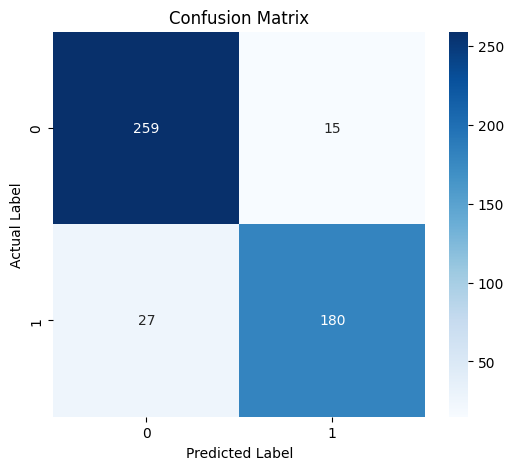

In [14]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# 2. Evaluate and Visualize results
def plot_performance(history):
    # Retrieve predictions and true labels for the validation set
    y_true = []
    y_pred = []
    
    for images, labels in val_ds:
        preds = model.predict(images, verbose=0)
        y_true.extend(labels.numpy())
        # Since it's sigmoid, values > 0.5 are class 1, else class 0
        y_pred.extend((preds > 0.5).astype("int32"))

    # Generate Confusion Matrix
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title('Confusion Matrix')
    plt.ylabel('Actual Label')
    plt.xlabel('Predicted Label')
    plt.show()

plot_performance(history)

In [ ]:
model.save('tb_bm_model.keras')

In [ ]:
model.evaluate(test_ds)

63/63 ━━━━━━━━━━━━━━━━━━━━ 8s 125ms/step - accuracy: 0.7672 - loss: 0.4943


[0.49433475732803345, 0.7672197222709656]

In [ ]:
import numpy as np 
import matplotlib.pyplot as plt
import 

def create_confusion_matrix(
    model: str, 
    eval_ds
): 
